# Modelo de Red FeedForward Base

Modelo base (baseline) de red para clasificar EuroSAT RGB (10 clases, 64x64x3). Es solo referencia para comparar contra la CNN del siguiente avance.

## 1. Configuración

In [1]:
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import train_test_split

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR_DATOS = RAIZ / "data" / "EuroSAT"
DIR_RESULTADOS = RAIZ / "resultados"
DIR_FIGURAS = DIR_RESULTADOS / "figures"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

TAM_LOTE = 64
# Entrenamiento en la GPU (CUDA); si no hay GPU se detiene para no entrenar la CNN en CPU por horas
if not torch.cuda.is_available():
    raise RuntimeError("No se detectó una GPU con CUDA en este entorno (torch %s)." % torch.__version__)
dispositivo = torch.device("cuda:0")
print("Dispositivo:", dispositivo, "|", torch.cuda.get_device_name(0), "| torch", torch.__version__)

Dispositivo: cuda:0 | NVIDIA GeForce RTX 4050 Laptop GPU | torch 2.14.1+cu126


## 2. Datos

In [2]:
# Carpetas en orden alfabético
clases = sorted(d.name for d in DIR_DATOS.iterdir() if d.is_dir())
rutas, etiquetas = [], []
for idx, clase in enumerate(clases):
    for ruta in sorted((DIR_DATOS / clase).glob("*.jpg")):
        rutas.append(ruta)
        etiquetas.append(idx)

X = np.stack([np.array(Image.open(r).convert("RGB"), dtype=np.uint8) for r in rutas])
y = np.array(etiquetas, dtype=np.int64)

assert len(clases) == 10
assert len(X) == 27000
assert X.shape[1:] == (64, 64, 3)
print(clases)
print("X:", X.shape, X.dtype, "| y:", y.shape)

['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
X: (27000, 64, 64, 3) uint8 | y: (27000,)


In [3]:
# Partición 70/15/15. El test solo no se evalúa en este avance
X_ent, X_resto, y_ent, y_resto = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
X_val, X_prueba, y_val, y_prueba = train_test_split(
    X_resto, y_resto, test_size=0.50, stratify=y_resto, random_state=SEMILLA)
print("Entrenamiento:", len(X_ent), "| Validación:", len(X_val), "| Prueba (apartada):", len(X_prueba))

def a_tensor(imagenes):
    return torch.from_numpy(imagenes.astype(np.float32) / 255.0)

Xt_ent, Xt_val = a_tensor(X_ent).to(dispositivo), a_tensor(X_val).to(dispositivo)
yt_ent, yt_val = torch.from_numpy(y_ent).to(dispositivo), torch.from_numpy(y_val).to(dispositivo)

Entrenamiento: 18900 | Validación: 4050 | Prueba (apartada): 4050


## 3. Modelo

In [4]:
def crear_modelo(capas=(256, 128)):
    # Flatten -> (Dense + ReLU + Dropout 0.5) por capa oculta -> Dense 10 (el softmax va en la pérdida)
    bloques, entrada = [nn.Flatten()], 64 * 64 * 3
    for unidades in capas:
        lineal = nn.Linear(entrada, unidades)
        nn.init.kaiming_normal_(lineal.weight, nonlinearity="relu")  
        nn.init.zeros_(lineal.bias)
        bloques += [lineal, nn.ReLU(), nn.Dropout(0.5)]
        entrada = unidades
    bloques.append(nn.Linear(entrada, 10))
    return nn.Sequential(*bloques)

def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())

assert contar_parametros(crear_modelo((256, 128))) == 3_180_170
print(crear_modelo((256, 128)))
print("Parámetros:", f"{contar_parametros(crear_modelo((256, 128))):,}")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=12288, out_features=256, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=256, out_features=128, bias=True)
  (5): ReLU()
  (6): Dropout(p=0.5, inplace=False)
  (7): Linear(in_features=128, out_features=10, bias=True)
)
Parámetros: 3,180,170


## 4. Entrenamiento del modelo base y curvas

In [5]:
def entrenar(capas, lr, epocas, semilla=SEMILLA):
    """Entrena con época fija (sin early stopping) y devuelve el modelo y su historial por época."""
    torch.manual_seed(semilla)
    modelo = crear_modelo(capas).to(dispositivo)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    perdida_fn = nn.CrossEntropyLoss()  
    generador = torch.Generator().manual_seed(semilla)
    historial = {"perdida_ent": [], "exactitud_ent": [], "perdida_val": [], "exactitud_val": []}

    for _ in range(epocas):
        modelo.train()
        orden = torch.randperm(len(Xt_ent), generator=generador).to(dispositivo)
        suma_perdida, aciertos = 0.0, 0
        for i in range(0, len(orden), TAM_LOTE):
            idx = orden[i:i + TAM_LOTE]
            salida = modelo(Xt_ent[idx])
            perdida = perdida_fn(salida, yt_ent[idx])
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()
            suma_perdida += perdida.item() * len(idx)
            aciertos += (salida.argmax(1) == yt_ent[idx]).sum().item()
        
        historial["perdida_ent"].append(suma_perdida / len(Xt_ent))
        historial["exactitud_ent"].append(aciertos / len(Xt_ent))

        modelo.eval()
        with torch.no_grad():
            salida_val = modelo(Xt_val)
            historial["perdida_val"].append(perdida_fn(salida_val, yt_val).item())
            historial["exactitud_val"].append((salida_val.argmax(1) == yt_val).float().mean().item())
    return modelo, historial

def graficar_curvas(historial, titulo, archivo):
    fig, (ax_p, ax_e) = plt.subplots(1, 2, figsize=(11, 4))
    ep = range(1, len(historial["perdida_ent"]) + 1)
    ax_p.plot(ep, historial["perdida_ent"], label="Entrenamiento")
    ax_p.plot(ep, historial["perdida_val"], label="Validación")
    ax_p.set(title="Pérdida", xlabel="Época", ylabel="Entropía cruzada"); ax_p.legend()
    ax_e.plot(ep, historial["exactitud_ent"], label="Entrenamiento")
    ax_e.plot(ep, historial["exactitud_val"], label="Validación")
    ax_e.set(title="Exactitud", xlabel="Época", ylabel="Exactitud"); ax_e.legend()
    fig.suptitle(titulo)
    fig.tight_layout()
    fig.savefig(DIR_FIGURAS / archivo, dpi=120)
    plt.show()

Modelo base entrenado en 37.7 s
Última época -> val exactitud: 0.2427 | val pérdida: 1.9025


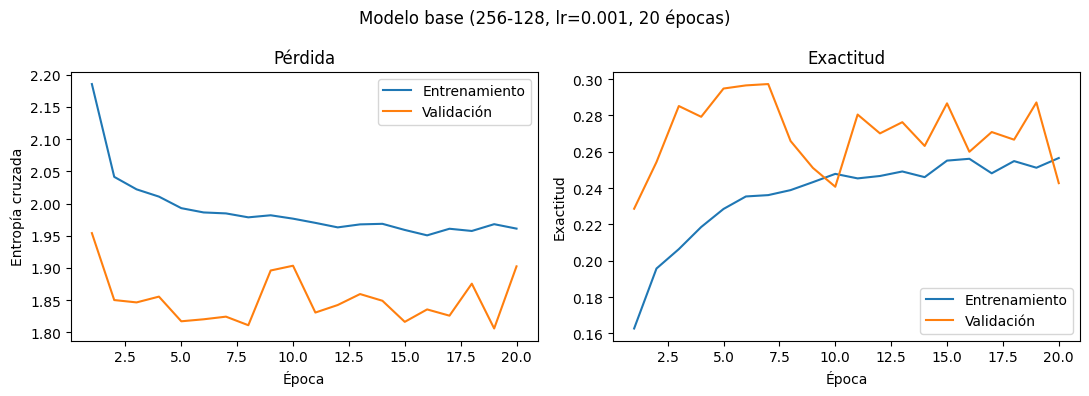

In [6]:
t0 = time.time()
modelo_base, hist_base = entrenar(capas=(256, 128), lr=1e-3, epocas=20)
print(f"Modelo base entrenado en {time.time() - t0:.1f} s")
print(f"Última época -> val exactitud: {hist_base['exactitud_val'][-1]:.4f} | val pérdida: {hist_base['perdida_val'][-1]:.4f}")
graficar_curvas(hist_base, "Modelo base (256-128, lr=0.001, 20 épocas)", "curvas_base.png")

## 5. Experimentos de hiperparámetros

Cada variante cambia una sola cosa respecto a R1 (base).

In [7]:
CONFIGURACIONES = {
    "R1": {"cambio": "base",          "capas": (256, 128), "lr": 1e-3, "epocas": 20},
    "R2": {"cambio": "lr = 0.0001",   "capas": (256, 128), "lr": 1e-4, "epocas": 20},
    "R3": {"cambio": "capas 512-256", "capas": (512, 256), "lr": 1e-3, "epocas": 20},
    "R4": {"cambio": "50 épocas",     "capas": (256, 128), "lr": 1e-3, "epocas": 50},
}

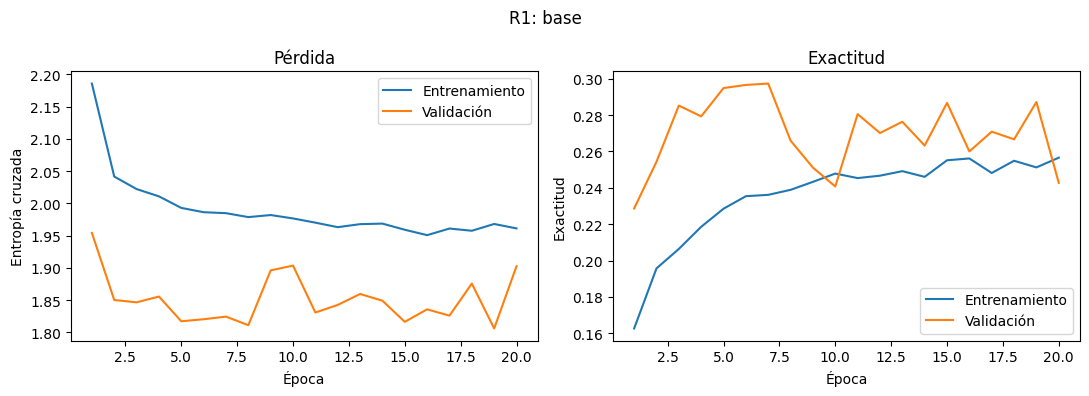

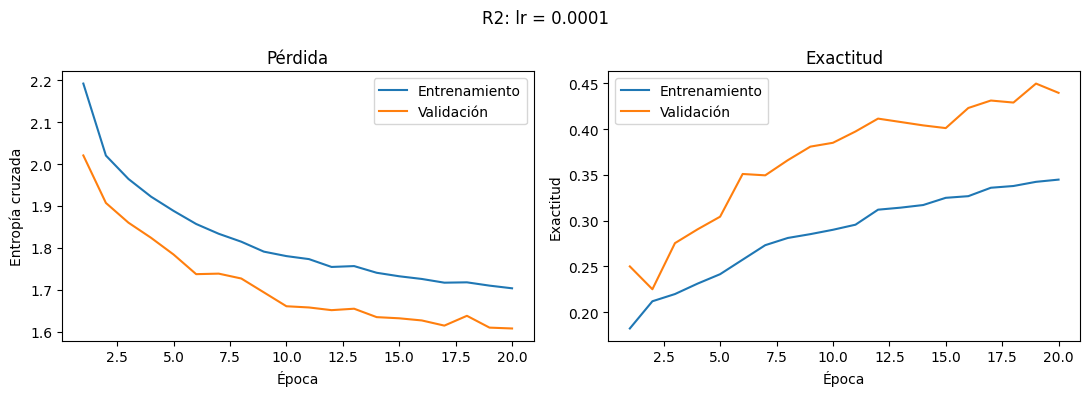

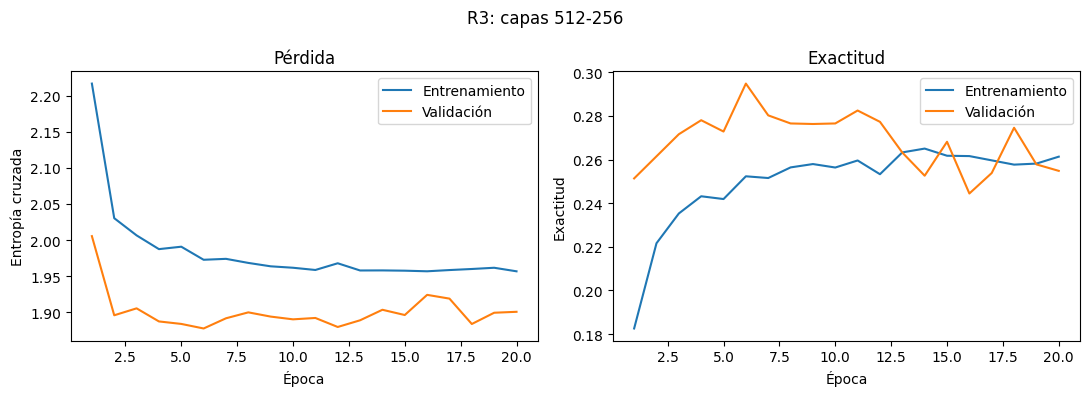

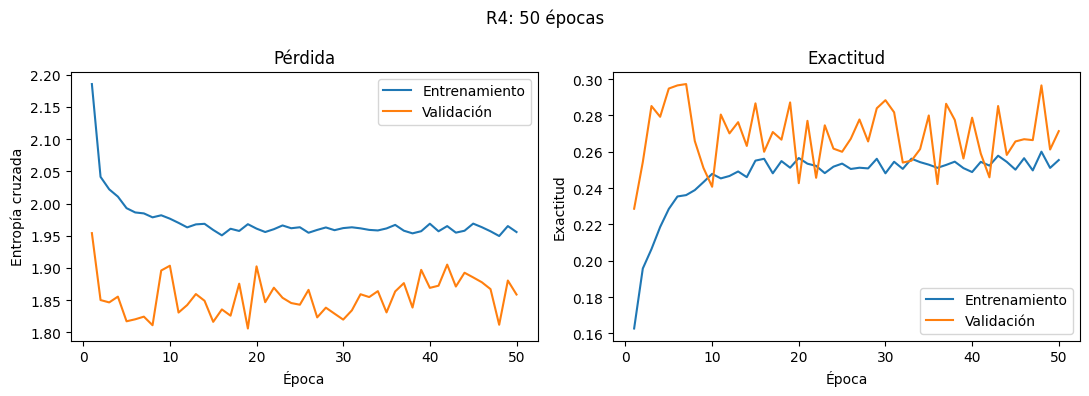

4 corridas en 104.0 s


In [8]:
historiales, filas = {}, []
t0 = time.time()
for id_corrida, cfg in CONFIGURACIONES.items():
    modelo, h = entrenar(cfg["capas"], cfg["lr"], cfg["epocas"])
    historiales[id_corrida] = h
    graficar_curvas(h, f"{id_corrida}: {cfg['cambio']}", f"curvas_{id_corrida}.png")
    mejor = int(np.argmax(h["exactitud_val"]))
    filas.append({
        "id": id_corrida,
        "cambio": cfg["cambio"],
        "parametros": contar_parametros(modelo),
        "exactitud_ent": h["exactitud_ent"][-1],
        "perdida_ent": h["perdida_ent"][-1],
        "exactitud_val": h["exactitud_val"][-1],
        "perdida_val": h["perdida_val"][-1],
        "mejor_exactitud_val": h["exactitud_val"][mejor],
        "epoca_mejor": mejor + 1,
    })
print(f"4 corridas en {time.time() - t0:.1f} s")

In [9]:
resumen = pd.DataFrame(filas)
resumen.to_csv(DIR_RESULTADOS / "resumen_redFFbase.csv", index=False)
resumen.round(4)

,id,cambio,parametros,exactitud_ent,perdida_ent,exactitud_val,perdida_val,mejor_exactitud_val,epoca_mejor
0,R1,base,3180170,0.2566,1.9611,0.2427,1.9025,0.2973,7
1,R2,lr = 0.0001,3180170,0.3447,1.7033,0.4395,1.6073,0.4496,19
2,R3,capas 512-256,6425866,0.2613,1.9568,0.2548,1.9008,0.2948,6
3,R4,50 épocas,3180170,0.2554,1.9558,0.2714,1.8588,0.2973,7


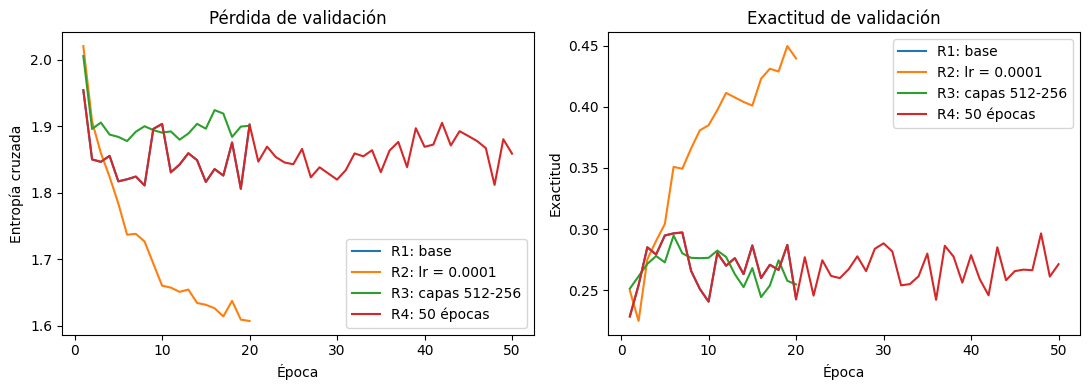

In [10]:
# Comparación de curvas de validación de las 4 
fig, (ax_p, ax_e) = plt.subplots(1, 2, figsize=(11, 4))
for id_corrida, h in historiales.items():
    etiqueta = f"{id_corrida}: {CONFIGURACIONES[id_corrida]['cambio']}"
    ep = range(1, len(h["perdida_val"]) + 1)
    ax_p.plot(ep, h["perdida_val"], label=etiqueta)
    ax_e.plot(ep, h["exactitud_val"], label=etiqueta)
ax_p.set(title="Pérdida de validación", xlabel="Época", ylabel="Entropía cruzada"); ax_p.legend()
ax_e.set(title="Exactitud de validación", xlabel="Época", ylabel="Exactitud"); ax_e.legend()
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "comparacion_validacion.png", dpi=120)
plt.show()

## 6. Observaciones

- El modelo base (R1) aprende muy poco: llega a ~27% de exactitud de validación al final (máximo 28.0% en la época 15), apenas por encima del azar (10%). Las curvas de validación son ruidosas, lo que sugiere que con lr = 0.001 el entrenamiento es inestable para esta red.
- R2 (lr = 0.0001) fue la mejor corrida: 42.0% de validación al final y 44.2% como máximo (época 18), con curvas más suaves y todavía mejorando. Bajar la tasa de aprendizaje fue el cambio con mayor efecto.
- R3 (capas 512-256, 6,425,866 parámetros) no mejoró: terminó en 17.5% de validación (máximo 26.8%). Más capacidad no ayudó con lr = 0.001.
- R4 (50 épocas) repite R1 hasta la época 20 (misma semilla) y su máximo es el mismo (28.0%, época 15); entrenar más no mejoró y terminó en 20.6%.
- En todas las corridas la exactitud de entrenamiento es baja y cercana a la de validación (en R1 y R2 incluso menor), porque se calcula con Dropout 0.5 activo y promediada durante la época. No hay señal de sobreajuste; el problema es de subajuste/optimización.
- Estos resultados son bajos y sirven solo como referencia para comparar contra la CNN. Solo se usó una semilla, así que las diferencias entre corridas son indicativas.

## 7. Modelo convolucional

In [11]:
def crear_cnn():
    bloques, entrada = [], 3
    for filtros in (32, 64, 128):
        for _ in range(2):
            conv = nn.Conv2d(entrada, filtros, kernel_size=3, padding=1)
            nn.init.kaiming_normal_(conv.weight, nonlinearity="relu")
            nn.init.zeros_(conv.bias)
            bloques += [conv, nn.BatchNorm2d(filtros), nn.ReLU()]
            entrada = filtros
        bloques.append(nn.MaxPool2d(2))

    oculta = nn.Linear(8 * 8 * 128, 128)
    nn.init.kaiming_normal_(oculta.weight, nonlinearity="relu")
    nn.init.zeros_(oculta.bias)
    bloques += [nn.Flatten(), oculta, nn.ReLU(), nn.Dropout(0.5), nn.Linear(128, 10)]
    return nn.Sequential(*bloques)

print(crear_cnn())
print("Parámetros:", f"{contar_parametros(crear_cnn()):,}")


Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (9): ReLU()
  (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (12): ReLU()
  (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (14): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15)

## 8. Entrenamiento y regularización

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display

DIR_MODELOS = DIR_RESULTADOS / "modelos"
DIR_MODELOS.mkdir(parents=True, exist_ok=True)

def lote_avance4(imagenes, etiquetas, idx, tipo, rng=None):
    imagenes_lote = imagenes[idx]
    # Aumento solo durante el entrenamiento: rotaciones de 90° y reflexiones.
    if rng is not None:
        imagenes_lote = imagenes_lote.copy()
        for j in range(len(imagenes_lote)):
            img = np.rot90(imagenes_lote[j], int(rng.integers(4)), axes=(0, 1))
            if rng.random() < 0.5:
                img = np.flip(img, axis=1)
            imagenes_lote[j] = img
    xb = a_tensor(imagenes_lote)
    if tipo == "cnn":
        xb = xb.permute(0, 3, 1, 2).contiguous()
    yb = torch.from_numpy(etiquetas[idx])
    return xb.to(dispositivo), yb.to(dispositivo)

@torch.no_grad()
def evaluar_avance4(modelo, imagenes, etiquetas, tipo):
    modelo.eval()
    perdida_total, predicciones = 0.0, []
    for inicio in range(0, len(imagenes), TAM_LOTE):
        idx = np.arange(inicio, min(inicio + TAM_LOTE, len(imagenes)))
        xb, yb = lote_avance4(imagenes, etiquetas, idx, tipo)
        salida = modelo(xb)
        perdida_total += nn.functional.cross_entropy(salida, yb).item() * len(idx)
        predicciones.extend(salida.argmax(1).cpu().tolist())
    predicciones = np.asarray(predicciones)
    return perdida_total / len(imagenes), np.mean(predicciones == etiquetas), predicciones

def entrenar_avance4(nombre, tipo, lr=1e-4, epocas=20, aumento=False):
    torch.manual_seed(SEMILLA)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEMILLA)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    modelo = (crear_cnn() if tipo == "cnn" else crear_modelo((256, 128))).to(dispositivo)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    generador = torch.Generator().manual_seed(SEMILLA)
    rng = np.random.default_rng(SEMILLA) if aumento else None
    historial = {k: [] for k in (
        "perdida_ent", "exactitud_ent", "perdida_ent_eval", "exactitud_ent_eval",
        "perdida_val", "exactitud_val")}
    mejor_clave, mejor_epoca = (-np.inf, -np.inf), None
    t0 = time.time()

    for epoca in range(epocas):
        modelo.train()
        orden = torch.randperm(len(X_ent), generator=generador).numpy()
        perdida_total, aciertos = 0.0, 0
        for inicio in range(0, len(orden), TAM_LOTE):
            idx = orden[inicio:inicio + TAM_LOTE]
            xb, yb = lote_avance4(X_ent, y_ent, idx, tipo, rng)
            optimizador.zero_grad()
            salida = modelo(xb)
            perdida = nn.functional.cross_entropy(salida, yb)
            perdida.backward()
            optimizador.step()
            perdida_total += perdida.item() * len(idx)
            aciertos += (salida.argmax(1) == yb).sum().item()

        # Mismos pesos y Dropout apagado para comparar entrenamiento y validación.
        pe, ae, _ = evaluar_avance4(modelo, X_ent, y_ent, tipo)
        pv, av, _ = evaluar_avance4(modelo, X_val, y_val, tipo)
        valores = (perdida_total / len(X_ent), aciertos / len(X_ent), pe, ae, pv, av)
        for clave, valor in zip(historial, valores):
            historial[clave].append(float(valor))

        # Checkpoint por validación; prueba no participa en esta selección.
        if (av, -pv) > mejor_clave:
            mejor_clave, mejor_epoca = (av, -pv), epoca + 1
            torch.save(modelo.state_dict(), DIR_MODELOS / f"{nombre}_mejor.pt")
        print(f"{nombre} | época {epoca + 1}/{epocas} | "
              f"ent: {ae:.4f} | val: {av:.4f} | pérdida val: {pv:.4f}", flush=True)

    pd.DataFrame(historial).to_csv(DIR_RESULTADOS / f"historial_{nombre}.csv", index=False)
    info = {"modelo": nombre, "tipo": tipo, "lr": lr, "epocas": epocas,
            "aumento": aumento, "parametros": contar_parametros(modelo),
            "mejor_epoca": mejor_epoca, "tiempo_s": time.time() - t0}
    return historial, info


In [13]:
# R2 se reentrena para guardar sus pesos; el código anterior solo conservaba historiales.
# Ambas CNN tienen la misma arquitectura, tasa, épocas y orden de lotes.
EXPERIMENTOS_A4 = {
    "MLP_R2":      {"tipo": "mlp", "lr": 1e-4, "epocas": 20, "aumento": False},
    "CNN_control": {"tipo": "cnn", "lr": 1e-4, "epocas": 20, "aumento": False},
    "CNN_aumento": {"tipo": "cnn", "lr": 1e-4, "epocas": 20, "aumento": True},
}
historiales_a4, info_a4 = {}, {}
for nombre, cfg in EXPERIMENTOS_A4.items():
    historial, info = entrenar_avance4(nombre, **cfg)
    historiales_a4[nombre], info_a4[nombre] = historial, info


MLP_R2 | época 1/20 | ent: 0.2511 | val: 0.2499 | pérdida val: 2.0205
MLP_R2 | época 2/20 | ent: 0.2303 | val: 0.2249 | pérdida val: 1.9071
MLP_R2 | época 3/20 | ent: 0.2837 | val: 0.2753 | pérdida val: 1.8600
MLP_R2 | época 4/20 | ent: 0.2961 | val: 0.2904 | pérdida val: 1.8239
MLP_R2 | época 5/20 | ent: 0.3057 | val: 0.3042 | pérdida val: 1.7839
MLP_R2 | época 6/20 | ent: 0.3594 | val: 0.3509 | pérdida val: 1.7371
MLP_R2 | época 7/20 | ent: 0.3523 | val: 0.3494 | pérdida val: 1.7383
MLP_R2 | época 8/20 | ent: 0.3689 | val: 0.3659 | pérdida val: 1.7267
MLP_R2 | época 9/20 | ent: 0.3840 | val: 0.3807 | pérdida val: 1.6936
MLP_R2 | época 10/20 | ent: 0.3925 | val: 0.3849 | pérdida val: 1.6604
MLP_R2 | época 11/20 | ent: 0.4032 | val: 0.3973 | pérdida val: 1.6575
MLP_R2 | época 12/20 | ent: 0.4184 | val: 0.4114 | pérdida val: 1.6511
MLP_R2 | época 13/20 | ent: 0.4092 | val: 0.4077 | pérdida val: 1.6545
MLP_R2 | época 14/20 | ent: 0.4038 | val: 0.4040 | pérdida val: 1.6344
MLP_R2 | época 

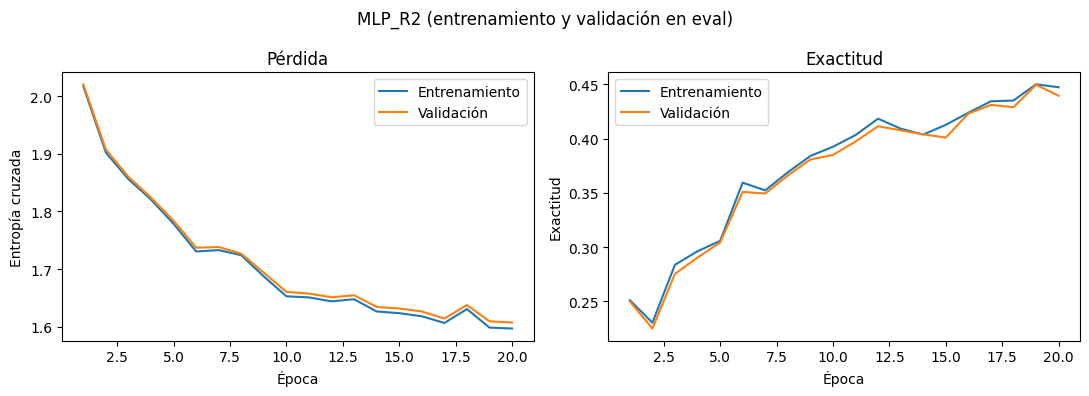

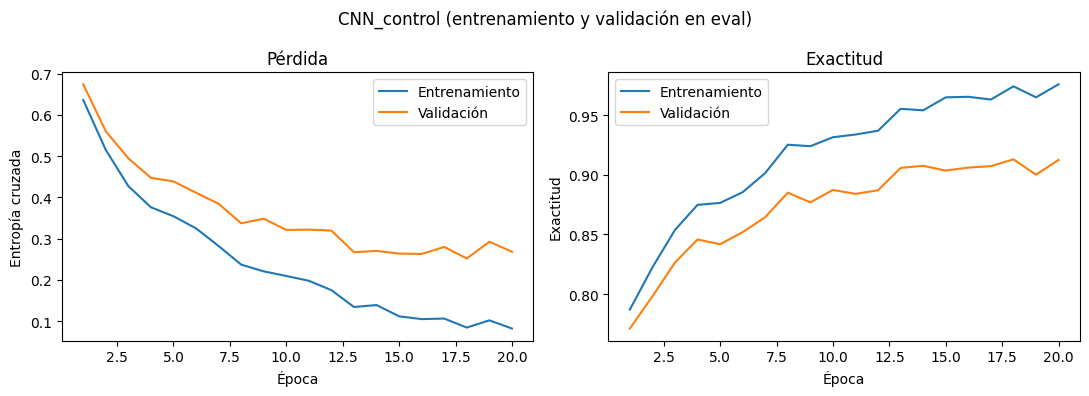

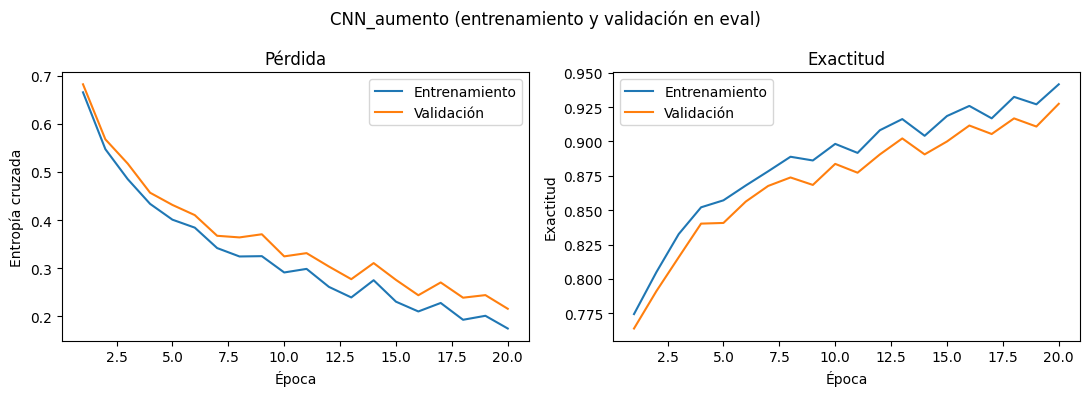

,parametros,epoca_mejor,exactitud_ent_eval,exactitud_val,perdida_val,brecha_pp,exactitud_val_final,perdida_val_final
modelo,,,,,,,,
MLP_R2,3180170,19,0.4501,0.4496,1.6094,0.0423,0.4395,1.6073
CNN_control,1337898,18,0.9740,0.9128,0.2518,6.1182,0.9123,0.2682
CNN_aumento,1337898,20,0.9416,0.9274,0.2156,1.4180,0.9274,0.2156


Efecto del aumento: CNN_aumento menos CNN_control.


,comparacion,delta_exactitud_val_pp,delta_perdida_val
0,Mejor checkpoint de cada CNN,1.4568,-0.0362
1,Última época de ambas,1.5062,-0.0526


In [14]:
for nombre, h in historiales_a4.items():
    # Reutilizamos la función original con entrenamiento medido en modo evaluación.
    h_eval = dict(h, perdida_ent=h["perdida_ent_eval"], exactitud_ent=h["exactitud_ent_eval"])
    graficar_curvas(h_eval, f"{nombre} (entrenamiento y validación en eval)",
                   f"curvas_{nombre}.png")

filas_a4 = []
for nombre, h in historiales_a4.items():
    info = info_a4[nombre]
    k = info["mejor_epoca"] - 1
    filas_a4.append({
        "modelo": nombre,
        "parametros": info["parametros"],
        "epoca_mejor": k + 1,
        "exactitud_ent_eval": h["exactitud_ent_eval"][k],
        "exactitud_val": h["exactitud_val"][k],
        "perdida_val": h["perdida_val"][k],
        "brecha_pp": 100 * (h["exactitud_ent_eval"][k] - h["exactitud_val"][k]),
        "exactitud_val_final": h["exactitud_val"][-1],
        "perdida_val_final": h["perdida_val"][-1],
    })
comparacion_a4 = pd.DataFrame(filas_a4).set_index("modelo")
comparacion_a4.to_csv(DIR_RESULTADOS / "comparacion_validacion_a4.csv")
display(comparacion_a4.round(4))

control, aumento = comparacion_a4.loc["CNN_control"], comparacion_a4.loc["CNN_aumento"]
efecto_aumento = pd.DataFrame({
    "comparacion": ["Mejor checkpoint de cada CNN", "Última época de ambas"],
    "delta_exactitud_val_pp": [
        100 * (aumento.exactitud_val - control.exactitud_val),
        100 * (aumento.exactitud_val_final - control.exactitud_val_final)],
    "delta_perdida_val": [
        aumento.perdida_val - control.perdida_val,
        aumento.perdida_val_final - control.perdida_val_final],
})
print("Efecto del aumento: CNN_aumento menos CNN_control.")
display(efecto_aumento.round(4))
efecto_aumento.to_csv(DIR_RESULTADOS / "efecto_aumento.csv", index=False)
# Una brecha menor no basta: revisar también desempeño y tendencia de las curvas.


## 9. Comparación y evaluación final

CNN seleccionada: CNN_aumento
Modelo elegido por validación: CNN_aumento


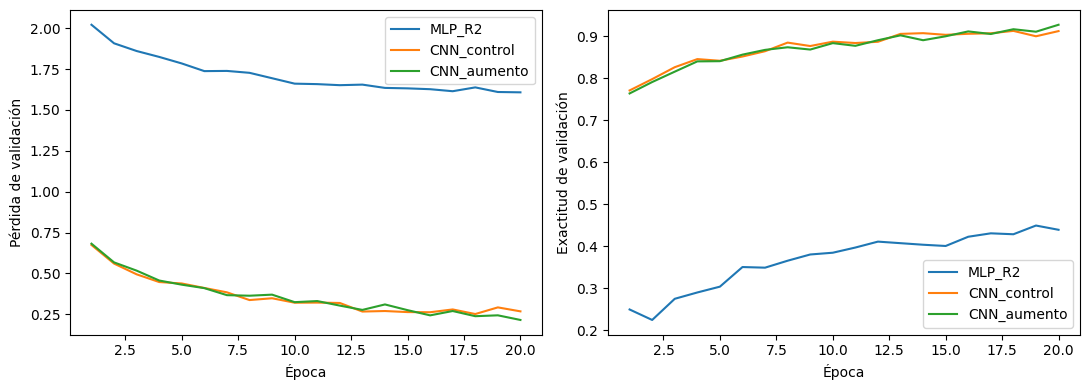

In [15]:
# Elegimos los modelos por validación antes de consultar prueba.
orden_a4 = comparacion_a4.sort_values(
    ["exactitud_val", "perdida_val"], ascending=[False, True], kind="stable")
cnn_elegida = next(nombre for nombre in orden_a4.index if nombre.startswith("CNN"))
modelo_elegido = orden_a4.index[0]
print("CNN seleccionada:", cnn_elegida)
print("Modelo elegido por validación:", modelo_elegido)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for nombre, h in historiales_a4.items():
    ep = range(1, len(h["perdida_val"]) + 1)
    axes[0].plot(ep, h["perdida_val"], label=nombre)
    axes[1].plot(ep, h["exactitud_val"], label=nombre)
axes[0].set(xlabel="Época", ylabel="Pérdida de validación")
axes[1].set(xlabel="Época", ylabel="Exactitud de validación")
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "comparacion_validacion_a4.png", dpi=150)
plt.show()


In [16]:
# Evaluación final: mismas imágenes de prueba para la MLP y la CNN seleccionada.
# No ajustar hiperparámetros ni cambiar la selección después de consultar estos resultados.
resultados_prueba = []
predicciones_a4 = {}
for nombre in ("MLP_R2", cnn_elegida):
    tipo = EXPERIMENTOS_A4[nombre]["tipo"]
    modelo_eval = (crear_cnn() if tipo == "cnn" else crear_modelo((256, 128))).to(dispositivo)
    modelo_eval.load_state_dict(torch.load(
        DIR_MODELOS / f"{nombre}_mejor.pt", map_location=dispositivo, weights_only=True))
    perdida, exactitud, pred = evaluar_avance4(modelo_eval, X_prueba, y_prueba, tipo)
    predicciones_a4[nombre] = pred
    resultados_prueba.append({
        "modelo": nombre, "exactitud": exactitud, "perdida": perdida,
        "f1_macro": f1_score(y_prueba, pred, average="macro", zero_division=0),
        "f1_ponderado": f1_score(y_prueba, pred, average="weighted", zero_division=0),
    })
    reporte = classification_report(
        y_prueba, pred, labels=np.arange(len(clases)), target_names=clases,
        output_dict=True, zero_division=0)
    pd.DataFrame(reporte).T.to_csv(DIR_RESULTADOS / f"reporte_{nombre}.csv")
    print(nombre)
    print(classification_report(
        y_prueba, pred, labels=np.arange(len(clases)), target_names=clases,
        digits=4, zero_division=0))
    del modelo_eval

tabla_prueba = pd.DataFrame(resultados_prueba).set_index("modelo")
tabla_prueba.to_csv(DIR_RESULTADOS / "comparacion_prueba_a4.csv")
display(tabla_prueba.round(4))
delta = 100 * (tabla_prueba.loc[cnn_elegida, "exactitud"] - tabla_prueba.loc["MLP_R2", "exactitud"])
print(f"Diferencia de exactitud CNN - MLP en prueba: {delta:+.2f} puntos porcentuales.")
print("Modelo conservado según validación:", modelo_elegido)


MLP_R2
                      precision    recall  f1-score   support

          AnnualCrop     0.4619    0.4311    0.4460       450
              Forest     0.5795    0.9067    0.7071       450
HerbaceousVegetation     0.3468    0.1911    0.2464       450
             Highway     0.2394    0.0453    0.0762       375
          Industrial     0.5579    0.7067    0.6235       375
             Pasture     0.5380    0.3300    0.4091       300
       PermanentCrop     0.3277    0.2080    0.2545       375
         Residential     0.3231    0.7044    0.4430       450
               River     0.3142    0.4240    0.3610       375
             SeaLake     0.9283    0.4600    0.6152       450

            accuracy                         0.4519      4050
           macro avg     0.4617    0.4407    0.4182      4050
        weighted avg     0.4664    0.4519    0.4252      4050

CNN_aumento
                      precision    recall  f1-score   support

          AnnualCrop     0.9032    0.9333    0.

,exactitud,perdida,f1_macro,f1_ponderado
modelo,,,,
MLP_R2,0.4519,1.5999,0.4182,0.4252
CNN_aumento,0.9301,0.2055,0.9282,0.9300


Diferencia de exactitud CNN - MLP en prueba: +47.83 puntos porcentuales.
Modelo conservado según validación: CNN_aumento


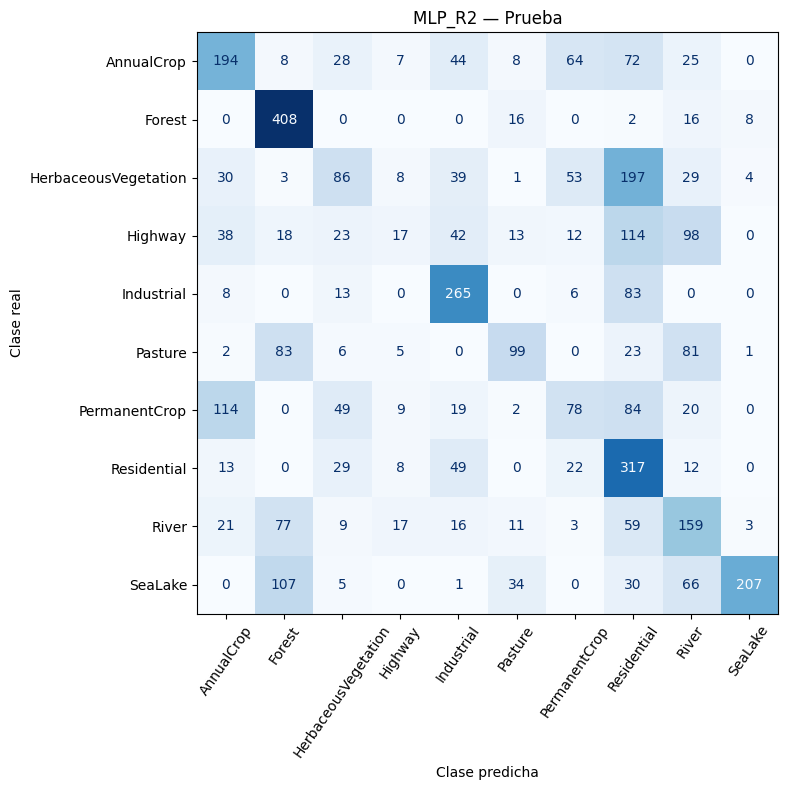

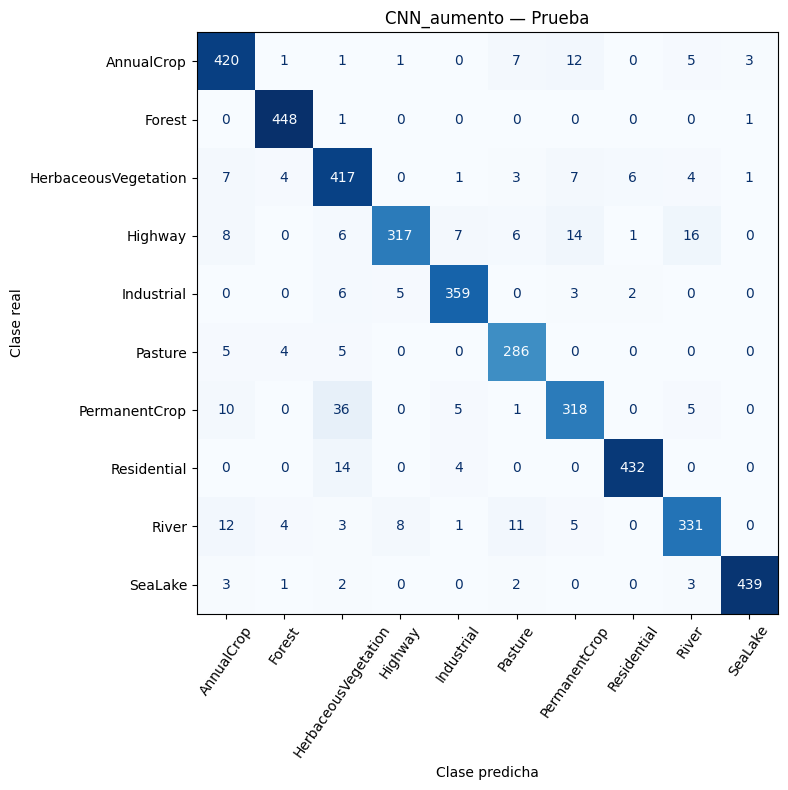

In [17]:
for nombre, pred in predicciones_a4.items():
    matriz = confusion_matrix(y_prueba, pred, labels=np.arange(len(clases)))
    pd.DataFrame(matriz, index=clases, columns=clases).to_csv(
        DIR_RESULTADOS / f"matriz_confusion_{nombre}.csv")
    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(matriz, display_labels=clases).plot(
        ax=ax, cmap="Blues", xticks_rotation=55, colorbar=False, values_format="d")
    ax.set(title=f"{nombre} — Prueba", xlabel="Clase predicha", ylabel="Clase real")
    fig.tight_layout()
    fig.savefig(DIR_FIGURAS / f"matriz_confusion_{nombre}.png", dpi=150)
    plt.show()
